# Data Collection

## Setup

In [ ]:
import torch
import polars as pl

from privacy_and_grokking.artifacts.cache import get_artifact_path, get_training_config
from privacy_and_grokking.artifacts.local import mlflow_export_cache_path, local_run_margin_attack_data
from privacy_and_grokking.datasets import GpuDataset
from privacy_and_grokking.utils import get_device, Logger
from shared import preprocess_metrics_df, SETUPS

/Users/ronholzapfel/Documents/private/privacy-and-grokking/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Run

In [2]:
metrics_df_v1 = preprocess_metrics_df(pl.read_parquet(mlflow_export_cache_path("canary-selection-v1")))
metrics_df_v2 = preprocess_metrics_df(pl.read_parquet(mlflow_export_cache_path("canary-selection-v2")))
metrics_df = pl.concat([metrics_df_v1, metrics_df_v2], how="diagonal")

In [3]:
metrics_df.head()

run_id,run_name,step,timestamp,epoch,eval/generalization_gap,eval/nc/nc1,eval/nc/nc2_equinorm_weights,eval/nc/nc2_equiangularity,eval/nc/nc2_maximal_angle_equiangularity,eval/nc/nc4_test,eval/nc/nc2_equinorm,eval/nc/nc2_equiangularity_weights,eval/nc/nc2_maximal_angle_equiangularity_weights,eval/nc/nc4,eval/nc/nc3,eval/nc/rnc1/train_impl,eval/nc/rnc1/train,eval/nc/rnc1/train_mean_test_variance_impl,eval/nc/rnc1/test_impl,eval/nc/rnc1/train_mean_test_variance,eval/nc/rnc1/test,eval/train/canary_accuracy,eval/train/accuracy,eval/train/canary_loss/cross_entropy/mean,eval/train/canary_loss/cross_entropy/std,eval/train/canary_loss/mse/mean,eval/train/canary_loss/mse/std,eval/train/loss/cross_entropy/mean,eval/train/loss/cross_entropy/std,eval/train/loss/mse/std,eval/train/loss/mse/mean,eval/test/canary_accuracy,eval/test/accuracy,eval/test/canary_loss/mse/mean,eval/test/canary_loss/mse/std,eval/test/canary_loss/cross_entropy/mean,…,eval/train/canary_loss/mse_prob/mean,eval/train/canary_loss/mse_prob/std,eval/train/loss/mse/top10_idx_3,eval/train/loss/mse/top10_idx_9,eval/train/loss/mse/top10_share,eval/train/loss/mse/top10_idx_4,eval/train/loss/mse/top10_idx_0,eval/train/loss/mse/top10_idx_7,eval/train/loss/mse/top10_idx_5,eval/train/loss/mse/top10_idx_8,eval/train/loss/mse/top10_idx_2,eval/train/loss/mse/top10_idx_6,eval/train/loss/mse/top10_idx_1,eval/train/loss/mse_prob/top10_idx_1,eval/train/loss/mse_prob/std,eval/train/loss/mse_prob/top10_idx_6,eval/train/loss/mse_prob/top10_idx_8,eval/train/loss/mse_prob/top10_idx_2,eval/train/loss/mse_prob/top10_idx_5,eval/train/loss/mse_prob/top10_idx_7,eval/train/loss/mse_prob/top10_idx_0,eval/train/loss/mse_prob/mean,eval/train/loss/mse_prob/top10_idx_4,eval/train/loss/mse_prob/top10_idx_3,eval/train/loss/mse_prob/top10_idx_9,eval/train/loss/mse_prob/top10_share,eval/train/loss/cross_entropy/top10_idx_4,eval/train/loss/cross_entropy/top10_share,eval/train/loss/cross_entropy/top10_idx_3,eval/train/loss/cross_entropy/top10_idx_9,eval/train/loss/cross_entropy/top10_idx_7,eval/train/loss/cross_entropy/top10_idx_0,eval/train/loss/cross_entropy/top10_idx_8,eval/train/loss/cross_entropy/top10_idx_2,eval/train/loss/cross_entropy/top10_idx_5,eval/train/loss/cross_entropy/top10_idx_1,eval/train/loss/cross_entropy/top10_idx_6
str,str,i64,datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""003a54a7b3874e12b45472ef2bf706…","""SQUARE_WATERMARK_GROK_MNIST_MS…",0,2026-09-05 07:05:47.098,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""003a54a7b3874e12b45472ef2bf706…","""SQUARE_WATERMARK_GROK_MNIST_MS…",0,2026-09-05 07:05:12.020,0.0,-0.000305,2.020342,0.038248,0.242497,0.185493,0.9234,0.214121,0.058478,0.110666,0.931579,1.995042,0.350759,0.141888,0.350787,0.345635,0.126295,0.124347,0.1,0.077895,68.045837,60.762383,3974.813477,5751.144531,66.919189,50.410038,2755.906738,1816.020142,0.07,0.0782,2343.800537,2474.350098,73.447357,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""003a54a7b3874e12b45472ef2bf706…","""SQUARE_WATERMARK_GROK_MNIST_MS…",0,2026-09-05 07:04:21.507,null,-0.000305,2.020342,0.038248,0.242497,0.185493,0.9234,0.214121,0.058478,0.110666,0.931579,1.995042,0.350759,0.141888,0.350787,0.345635,0.126295,0.124347,0.1,0.077895,68.045837,60.762383,3974.813477,5751.144531,66.919189,50.410038,2755.906738,1816.020142,0.07,

In [4]:
# tmp = (pl.col("run_name").str.contains("MSE_MLP") & pl.col("run_name").str.contains("NO_GROK").not_()) # Remove when running for all.
run_ids = list(metrics_df.filter((pl.col("run_name").str.contains("LABEL_NOISE")) & (pl.col("run_name").str.contains_any(list(SETUPS.keys())))).unique(subset=["run_id"])["run_id"])

## Collect Distances

In [5]:
def maybe_gpu_dataset(dataset):
        if keep_on_gpu:
            return GpuDataset(dataset, device)
        return dataset

def safe_collate(batch):
    if isinstance(batch[0], tuple) and len(batch[0]) == 2:
        xs, ys = zip(*batch)
        if any(isinstance(y, torch.Tensor) for y in ys) and any(not isinstance(y, torch.Tensor) for y in ys):
            ys = [y if isinstance(y, torch.Tensor) else torch.tensor(y) for y in ys]
            batch = list(zip(xs, ys))
    return torch.utils.data.default_collate(batch)

def get_dl_kwargs(dataset):
    is_gpu = isinstance(dataset, GpuDataset)
    return {
        "batch_size": 200,
        "num_workers": 0 if is_gpu else config.num_workers,
        "pin_memory": (config.num_workers > 0 and keep_on_gpu and not is_gpu),
        "persistent_workers": (config.num_workers > 0 and not is_gpu),
        "collate_fn": safe_collate,
    }

In [6]:
for idx, run_id in enumerate(run_ids):
    for checkpoint in range(0, 150_001, 10_000):
        print(f"Run {idx}/{len(run_ids)}: Checkpoint: {checkpoint}")
        try:
            checkpoint_path = get_artifact_path(run_id=run_id, artifact_path=f"checkpoints/{checkpoint}/model.pth")
        except:
            print(f"Failed to download checkpoint {checkpoint} for run {run_id}")
            continue
        config = get_training_config(run_id=run_id)
        Logger().setup()
        keep_on_gpu = torch.cuda.is_available()
        device = get_device()
        data_container = config.data()
        model = config.model(
            input_dim=data_container.input_shape,
            num_classes=data_container.num_classes,
        )
        model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
        model.to(device)
        model.train()

        norm_mean = None
        norm_std = None
        if data_container.normalization is not None:
            norm_mean = torch.tensor(data_container.normalization.mean, device=device).view(-1, 1, 1)
            norm_std = torch.tensor(data_container.normalization.std, device=device).view(-1, 1, 1)
        
        train_ds = maybe_gpu_dataset(data_container.train)
        train_loader = torch.utils.data.DataLoader(train_ds, **get_dl_kwargs(train_ds))

        train_canary_ds = maybe_gpu_dataset(data_container.train_canary)
        train_canary_loader = torch.utils.data.DataLoader(train_canary_ds, **get_dl_kwargs(train_canary_ds))

        test_ds = maybe_gpu_dataset(data_container.test)
        test_loader = torch.utils.data.DataLoader(test_ds, **get_dl_kwargs(test_ds))

        test_canary_ds = maybe_gpu_dataset(data_container.test_canary)
        test_canary_loader = torch.utils.data.DataLoader(test_canary_ds, **get_dl_kwargs(test_canary_ds))

        classifier_weights = list(model.classifier().parameters())[0]
        w_dist = torch.cdist(classifier_weights, classifier_weights).clamp(min=1e-12) # On diagonal always 0
        iu, ju = torch.triu_indices(classifier_weights.shape[0], classifier_weights.shape[0], offset=1)

        dfs = []
        for type, loader in [("train", train_loader), ("train_canary", train_canary_loader), ("test", test_loader), ("test_canary", test_canary_loader)]:
            actual_list = []
            pred_list = []
            class_wise_distance_list = []
            distance_list = []
            feature_list = []

            with torch.no_grad():
                for x, y in loader:
                    x, y = x.to(device), y.to(device)
                    if norm_mean is not None and norm_std is not None:
                        x = (x - norm_mean) / norm_std
                    y_pred, z = model(x, verbose=True)
                    feature_list.append(z)
                    d_all = torch.cdist(z, classifier_weights)
                    
                    actual_list.append(y)
                    pred_list.append(y_pred.argmax(dim=-1))
                    distance_list.append(d_all)
                    class_wise_distance_list.append((y_pred[:, iu] - y_pred[:, ju]) / w_dist[iu, ju])

                class_wise_distances = torch.cat(class_wise_distance_list).T.numpy()
                distances = torch.cat(distance_list).T.numpy()
                features = torch.cat(feature_list).numpy()
                df_new = pl.DataFrame({"type": type, "pred": torch.cat(pred_list).numpy(), "actual": torch.cat(actual_list).numpy(), **{f"d{i}": distances[i] for i in range(distances.shape[0])}, **{f"cd-{iu[i]}-{ju[i]}": class_wise_distances[i] for i in range(class_wise_distances.shape[0])}, "feature": features})
                dfs.append(df_new)

        df = pl.concat(dfs)
        path = local_run_margin_attack_data(run_id, checkpoint)
        path.parent.mkdir(parents=True, exist_ok=True)
        df.write_parquet(path)

Run 0/54: Checkpoint: 0
{"log_file": "/var/folders/_r/9n6ndj_d7k5b5yds9vn86n200000gn/T/2026-10-25T12-57-28_gkd9illv.log", "event": "Logger initialized", "timestamp": "2026-10-25T11:57:28.311681Z", "level": "info"}
Run 0/54: Checkpoint: 10000
Run 0/54: Checkpoint: 20000
Run 0/54: Checkpoint: 30000
Run 0/54: Checkpoint: 40000
Run 0/54: Checkpoint: 50000
Run 0/54: Checkpoint: 60000
Run 0/54: Checkpoint: 70000
Run 0/54: Checkpoint: 80000
Run 0/54: Checkpoint: 90000
Run 0/54: Checkpoint: 100000
Run 0/54: Checkpoint: 110000
Run 0/54: Checkpoint: 120000
Run 0/54: Checkpoint: 130000
Run 0/54: Checkpoint: 140000
Run 0/54: Checkpoint: 150000
Run 1/54: Checkpoint: 0
Run 1/54: Checkpoint: 10000
Run 1/54: Checkpoint: 20000
Run 1/54: Checkpoint: 30000
Run 1/54: Checkpoint: 40000
Run 1/54: Checkpoint: 50000
Run 1/54: Checkpoint: 60000
Run 1/54: Checkpoint: 70000
Run 1/54: Checkpoint: 80000
Run 1/54: Checkpoint: 90000
Run 1/54: Checkpoint: 100000
Run 1/54: Checkpoint: 110000
Run 1/54: Checkpoint: 1200

Failed to download checkpoint 60000 for run 4166ce0921d142b49bb629eef2e4a493
Run 3/54: Checkpoint: 70000


Failed to download checkpoint 70000 for run 4166ce0921d142b49bb629eef2e4a493
Run 3/54: Checkpoint: 80000


Failed to download checkpoint 80000 for run 4166ce0921d142b49bb629eef2e4a493
Run 3/54: Checkpoint: 90000


Failed to download checkpoint 90000 for run 4166ce0921d142b49bb629eef2e4a493
Run 3/54: Checkpoint: 100000


...

Failed to download checkpoint 110000 for run 0a341d15fecf4c3fa471fb6a35fb5e26
Run 45/54: Checkpoint: 120000


Failed to download checkpoint 120000 for run 0a341d15fecf4c3fa471fb6a35fb5e26
Run 45/54: Checkpoint: 130000


Failed to download checkpoint 130000 for run 0a341d15fecf4c3fa471fb6a35fb5e26
Run 45/54: Checkpoint: 140000


Failed to download checkpoint 140000 for run 0a341d15fecf4c3fa471fb6a35fb5e26
Run 45/54: Checkpoint: 150000


Failed to download checkpoint 150000 for run 0a341d15fecf4c3fa471fb6a35fb5e26
Run 46/54: Checkpoint: 0
Run 46/54: Checkpoint: 10000
Run 46/54: Checkpoint: 20000
Run 46/54: Checkpoint: 30000
Run 46/54: Checkpoint: 40000
Run 46/54: Checkpoint: 50000
Run 46/54: Checkpoint: 60000
Run 46/54: Checkpoint: 70000
Run 46/54: Checkpoint: 80000
Run 46/54: Checkpoint: 90000
Run 46/54: Checkpoint: 100000
Run 46/54: Checkpoint: 110000
Run 46/54: Checkpoint: 120000
Run 46/54: Checkpoint: 130000
Run 46/54: Checkpoint: 140000
Run 46/54: Checkpoint: 150000
Run 47/54: Checkpoint: 0
Run 47/54: Checkpoint: 10000
Run 47/54: Checkpoint: 20000
Run 47/54: Checkpoint: 30000
Run 47/54: Checkpoint: 40000
Run 47/54: Checkpoint: 50000
Run 47/54: Checkpoint: 60000
Run 47/54: Checkpoint: 70000
Run 47/54: Checkpoint: 80000
Run 47/54: Checkpoint: 90000
Run 47/54: Checkpoint: 100000
Run 47/54: Checkpoint: 110000
Run 47/54: Checkpoint: 120000
Run 47/54: Checkpoint: 130000
Run 47/54: Checkpoint: 140000
Run 47/54: Checkpoin

In [ ]:
w_dist

tensor([[1.0000e-12, 4.5827e-01, 4.3774e-01, 4.4692e-01, 4.6010e-01, 4.5791e-01,
         6.1123e-01, 4.6478e-01, 4.7773e-01, 4.9280e-01],
        [4.5827e-01, 1.0000e-12, 4.4157e-01, 4.5032e-01, 4.6534e-01, 4.6173e-01,
         6.9047e-01, 4.6905e-01, 4.8208e-01, 4.9755e-01],
        [4.3774e-01, 4.4157e-01, 1.0000e-12, 4.3144e-01, 4.4671e-01, 4.4346e-01,
         6.0519e-01, 4.5050e-01, 4.6475e-01, 4.8067e-01],
        [4.4692e-01, 4.5032e-01, 4.3144e-01, 1.0000e-12, 4.5573e-01, 4.5267e-01,
         6.1245e-01, 4.5938e-01, 4.7361e-01, 4.8916e-01],
        [4.6010e-01, 4.6534e-01, 4.4671e-01, 4.5573e-01, 1.0000e-12, 4.6684e-01,
         6.2040e-01, 4.7325e-01, 4.8657e-01, 5.0171e-01],
        [4.5791e-01, 4.6173e-01, 4.4346e-01, 4.5267e-01, 4.6684e-01, 1.0000e-12,
         6.2069e-01, 4.7043e-01, 4.8446e-01, 4.9963e-01],
        [6.1123e-01, 6.9047e-01, 6.0519e-01, 6.1245e-01, 6.2040e-01, 6.2069e-01,
         1.0000e-12, 6.2419e-01, 6.3517e-01, 6.4655e-01],
        [4.6478e-01, 4.6905

## Attacks

In [79]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_auc_score, roc_curve

def plot_roc(membership, scores):
    auc_val = roc_auc_score(membership, scores)
    fpr, tpr, thresholds = roc_curve(membership, scores, drop_intermediate=True)

    plt.plot(fpr, tpr, lw=2, label=f"Ours (AUC = {auc_val:.3f})")
    plt.plot([0, 1], [0, 1], "--", color="gray", label="Random guess")
    plt.xlabel("False Positive Rate (FPR)")
    plt.ylabel("True Positive Rate (TPR)")
    plt.legend(loc="lower right")
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.show()

In [80]:
for run_id in run_ids:
    config = get_training_config(run_id=run_id)
    print(run_id, config.data.mask.model_index)

1c1f36ceade64664a2a13a1c968481ed 4
4e4e974897a3432e92b547a2535174a9 3
5ef3b7e613a44a97b5820436eed0c7cb 2
78dfb6381fef43f1bb66946ee467961a 1
8db2fdccab07431b88271c095c8a3340 5
f32c7e6585834823937b801942d05e1d 0


In [81]:
actual_column_expr = pl.when(pl.col("actual") <= 1).then(pl.col("cd-0-1"))
for i in range(2, 10):
    actual_column_expr = actual_column_expr.when(pl.col("actual") == i).then(pl.col(f"cd-0-{i}"))
actual_column_expr = actual_column_expr.otherwise(None)

In [165]:
def mean_for_actual_class(df):
    df_indexed = df.with_row_index("row_id")
    cd_cols = [col for col in df_indexed.columns if "cd" in col]
    melted = df_indexed.melt(
        id_vars=["row_id", "actual"],
        value_vars=cd_cols,
        variable_name="cd_col",
        value_name="val",
    )
    filtered = melted.filter(
        pl.col("cd_col").str.contains(pl.col("actual").cast(pl.String))
    )
    mean_df = filtered.group_by("row_id").agg(
        pl.col("val").mean().alias("mean_actual_cd")
    )
    return df_indexed.join(mean_df, on="row_id").drop("row_id")

In [238]:
df_attack = pl.read_parquet(local_run_margin_attack_data(run_ids[5], "150000"))
df_attack = df_attack.with_columns(cd_0=actual_column_expr)
df_attack = mean_for_actual_class(df_attack)
df_shadow = pl.read_parquet(local_run_margin_attack_data(run_ids[0], "150000"))
df_shadow = df_shadow.with_columns(cd_0=actual_column_expr)
df_shadow = mean_for_actual_class(df_shadow)

/var/folders/_r/9n6ndj_d7k5b5yds9vn86n200000gn/T/ipykernel_12756/592157004.py:4: DeprecationWarning: `DataFrame.melt` is deprecated; use `DataFrame.unpivot` instead, with `index` instead of `id_vars` and `on` instead of `value_vars`
  melted = df_indexed.melt(


## Visualization

In [249]:
from scipy.stats import gaussian_kde


def kde_mode(values, n_grid=2000):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) < 2:
        return np.nan

    kde = gaussian_kde(values, bw_method="scott")
    grid = np.linspace(values.min(), values.max(), n_grid)
    return grid[np.argmax(kde(grid))]

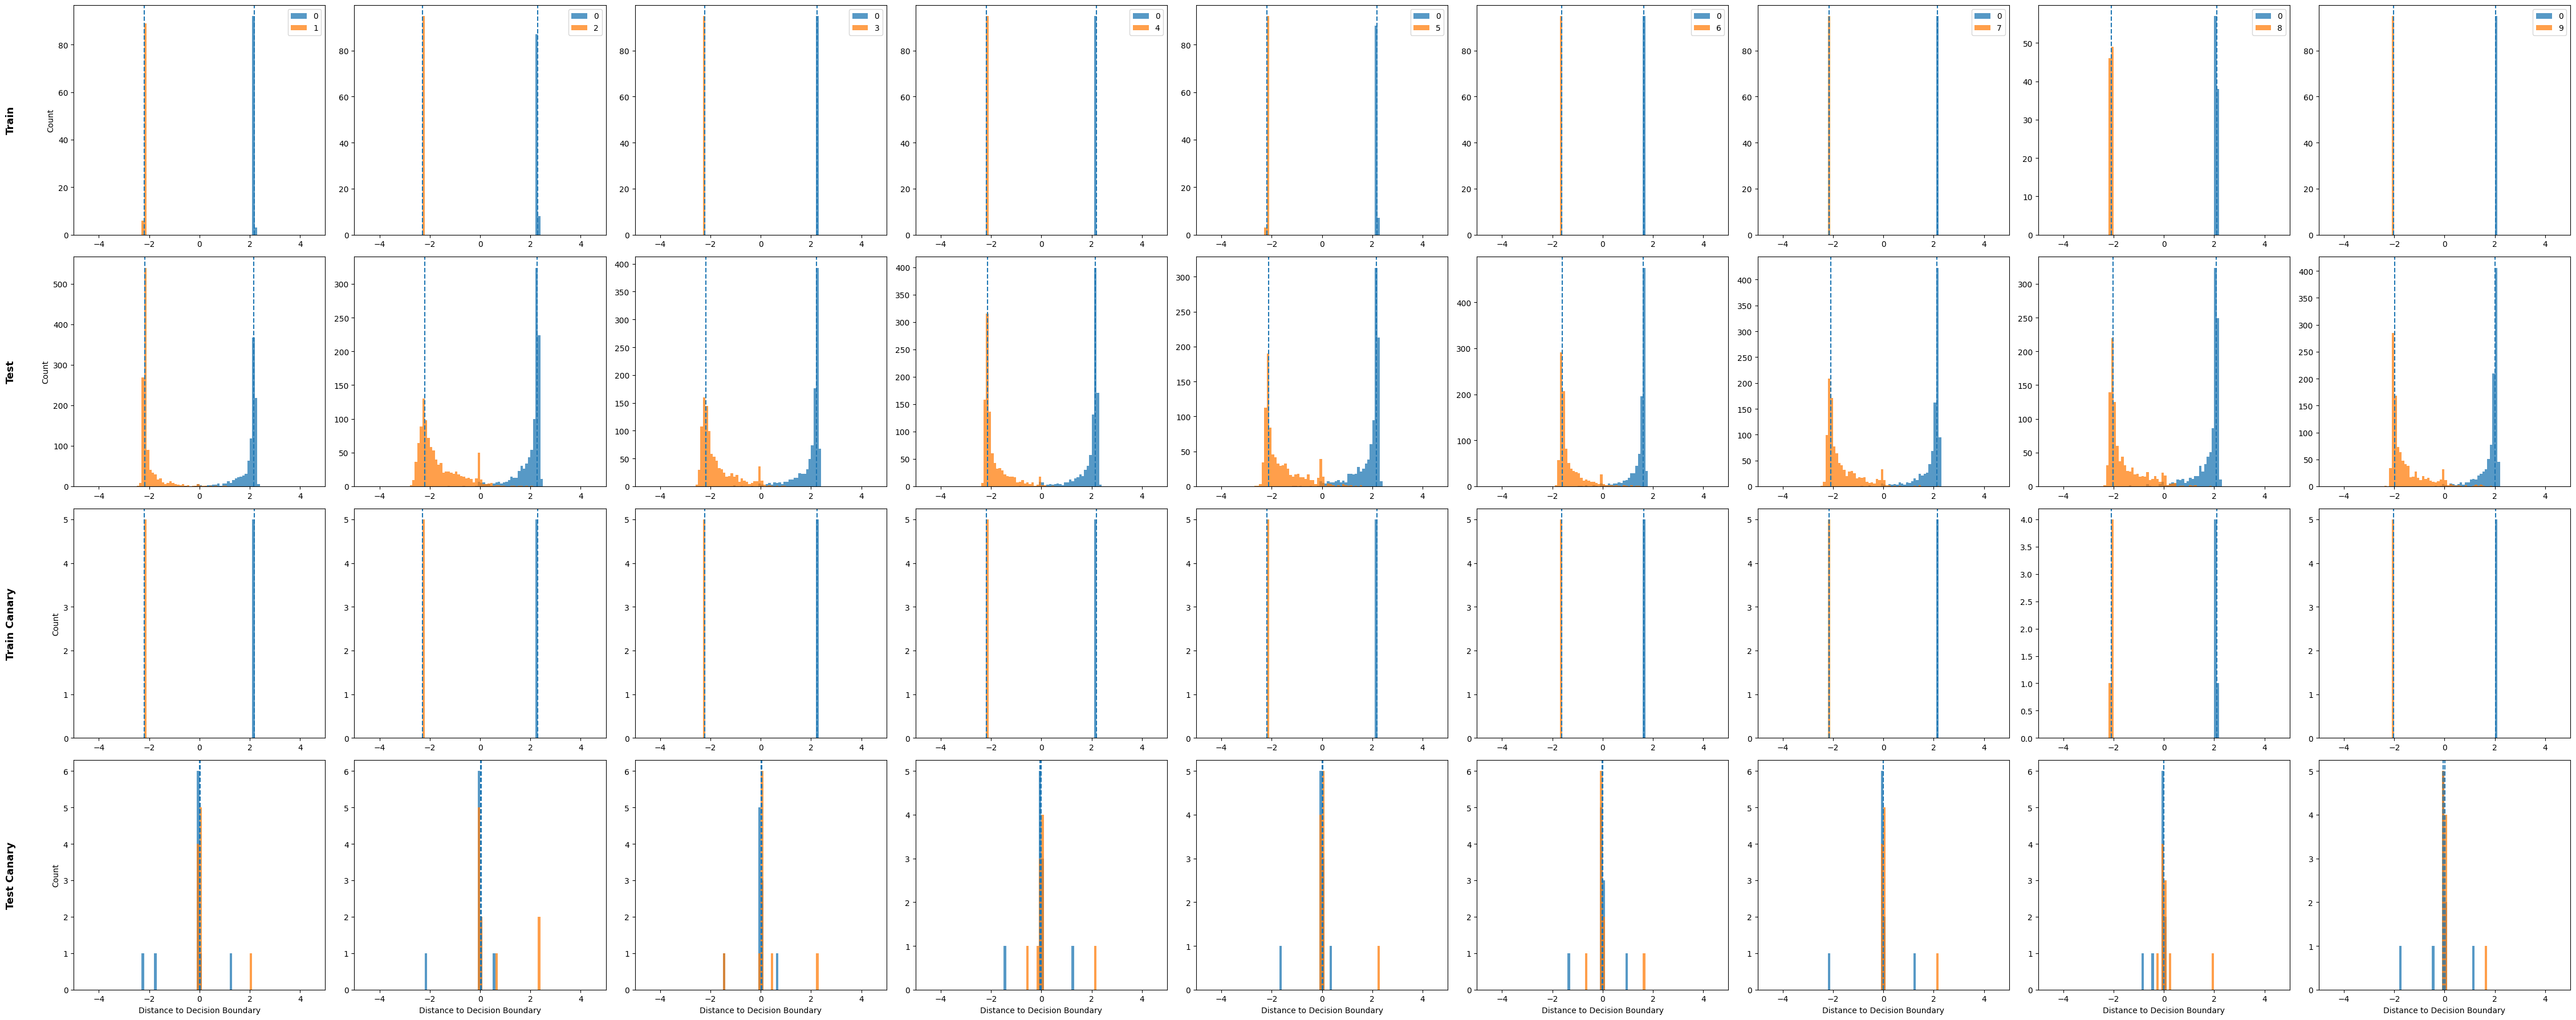

In [252]:
ROWS = ["train", "test", "train_canary", "test_canary"]
N_COLS = 9
N_ROWS = len(ROWS)

fig, axes = plt.subplots(N_ROWS, N_COLS, figsize=(5 * N_COLS, 4.5 * N_ROWS))

for row in range(N_ROWS):
    type = ROWS[row]
    df_type = df_attack.filter((pl.col("type") == type))
    df_type_0 = df_type.filter((pl.col("actual") == 0))

    for col in range(1, N_COLS+1):
        ax = axes[row, col-1]
        df_type_col = df_type.filter((pl.col("actual") == col))
        bins = np.linspace(-5, 5, 101)
        ax.axvline(kde_mode(df_type_0[f"cd-0-{col}"]), linestyle="--")
        ax.hist(df_type_0[f"cd-0-{col}"], bins=bins, label="0", alpha=0.75)
        # ax.axvline(df_type_col[f"cd-0-{col}"].mode(), linestyle="--")
        ax.axvline(kde_mode(df_type_col[f"cd-0-{col}"]), linestyle="--")
        ax.hist(df_type_col[f"cd-0-{col}"], bins=bins, label=col, alpha=0.75)
        # print(type, col, len(df_type_0), len(df_type_col), df_type_0[f"cd-0-{col}"].mean(), df_type_col[f"cd-0-{col}"].mean())
        ax.set_xlim(-5, 5)
        if row == 0:
            ax.legend()

    axes[row, 0].annotate(
        " ".join([s.capitalize() for s in type.split("_")]),
        xy=(-0.25, 0.5),
        xycoords="axes fraction",
        fontsize=13,
        fontweight="bold",
        ha="center",
        va="center",
        rotation=90,
    )
    axes[row, 0].set_ylabel("Count")

    # Y-Labels
    if row == N_ROWS - 1:
        for i in range(N_COLS):
            axes[row, i].set_xlabel("Distance to Decision Boundary")

plt.tight_layout()
# fig.savefig(PLOTS / f"canary_selection_v1_{str(date.today())}.pdf", format="pdf", bbox_inches="tight")

In [54]:
# TODO: Visualize Class mean vs. Distance to class mean

## Global Reference Distance across all Classes with Leakage (based on Train Data)

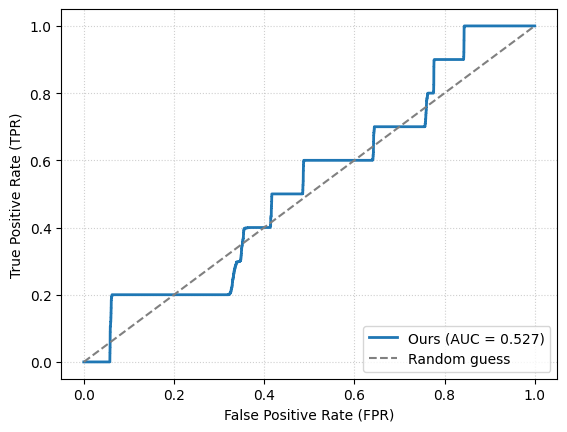

In [46]:
reference = df_attack.filter((pl.col("type") == "train"))["mean_actual_cd"].abs().median()
attacked = df_attack.filter(((pl.col("type") == "train") | (pl.col("type") == "test")))
scores = -(attacked["mean_actual_cd"].abs() - reference).abs()
plot_roc(attacked["type"] == "train", scores)

## Global Reference Distance for every Class Separate with Leakage (based on Train Data)

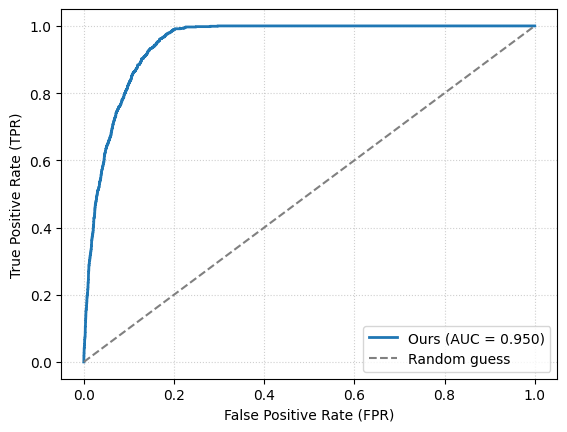

In [237]:
references = df_attack.filter((pl.col("type") == "train")).group_by("actual").agg(pl.col("mean_actual_cd").abs().median().alias("reference"))
attacked = df_attack.filter(((pl.col("type") == "train") | (pl.col("type") == "test"))).join(references, on="actual")
scores = -(attacked["mean_actual_cd"].abs() - attacked["reference"]).abs()
plot_roc(attacked["type"] == "train", scores)

## Global Reference Distance for one Class (0) with Leakage (based on Train Data)

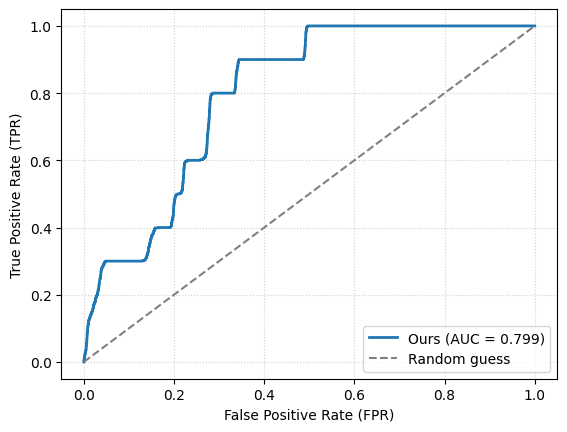

In [48]:
reference = df_attack.filter((pl.col("type") == "train"))["cd_0"].abs().median()
attacked = df_attack.filter(((pl.col("type") == "train") | (pl.col("type") == "test")))
scores = -(attacked["cd_0"].abs() - reference).abs()
plot_roc(attacked["type"] == "train", scores)

## Single Reference Distance per Class based on Class 0 with Leakage (based on Train Data)

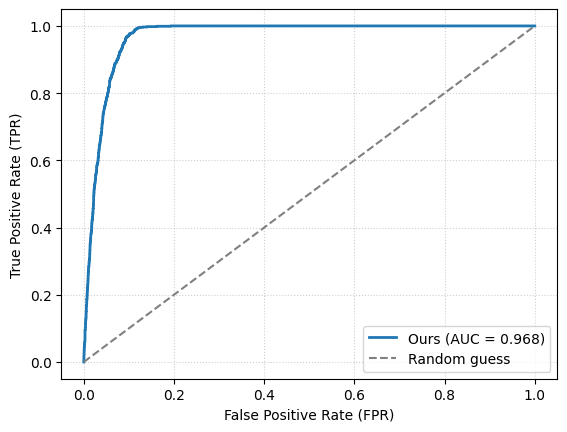

In [267]:
references = df_attack.filter((pl.col("type") == "train")).group_by("actual").agg(pl.col("cd_0").abs().median().alias("reference"))
attacked = df_attack.filter(((pl.col("type") == "train") | (pl.col("type") == "test"))).join(references, on="actual")
scores = -(attacked["cd_0"].abs() - attacked["reference"]).abs()
plot_roc(attacked["type"] == "train", scores)

In [268]:
references

actual,reference
i64,f32
0,2.186705
4,2.178461
9,2.026729
2,2.286852
6,1.638549
1,2.189728
3,2.234563
8,2.09962
7,2.149072


## Single Reference Distance per Class based on Class 0 Leakage Free based on Shadow Model

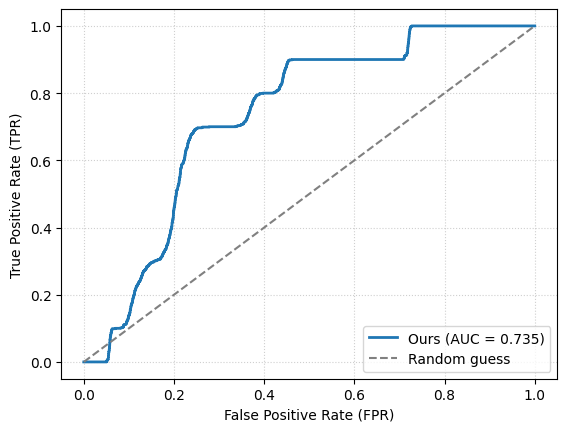

In [265]:
references = df_shadow.filter((pl.col("type") == "train")).group_by("actual").agg(pl.col("cd_0").abs().median().alias("reference"))
attacked = df_attack.filter(((pl.col("type") == "train") | (pl.col("type") == "test"))).join(references, on="actual")
scores = -(attacked["cd_0"].abs() - attacked["reference"]).abs()
plot_roc(attacked["type"] == "train", scores)

In [266]:
references

actual,reference
i64,f32
1,2.536551
7,2.626267
4,2.604836
9,2.336516
6,2.654496
0,2.532408
5,2.484563
2,2.54185
3,2.577867


## Single Reference Distance per Class based on Class 0 Leakage Free based on Test Data

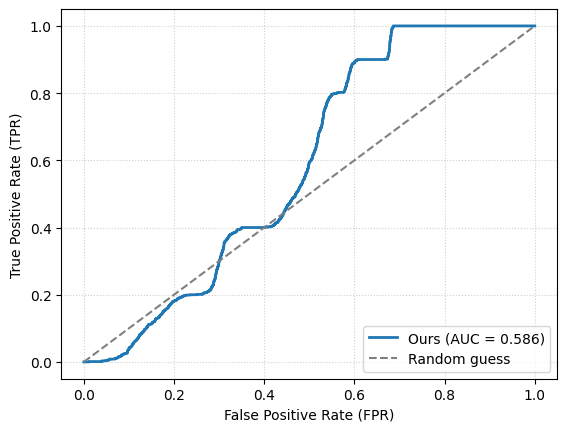

In [260]:
references = df_attack.filter((pl.col("type") == "test")).group_by("actual").agg(pl.col("cd_0").abs().median().alias("reference"))
attacked = df_attack.filter(((pl.col("type") == "train") | (pl.col("type") == "test"))).join(references, on="actual")
scores = -(attacked["cd_0"].abs() - attacked["reference"]).abs()
plot_roc(attacked["type"] == "train", scores)

In [261]:
references

actual,reference
i64,f32
3,2.047906
0,2.140084
9,1.882134
6,1.55233
7,1.970818
1,2.161003
4,2.092337
2,1.974852
8,1.93513


## Single Reference Distance per Class based on Class 0 Leakage Free based on Test Data estimating through KDE Mode

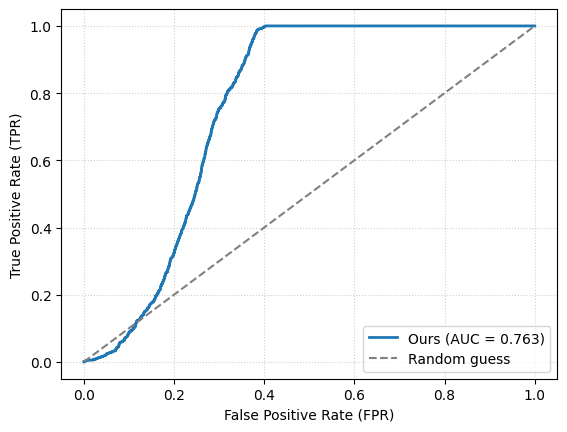

In [270]:
references = df_attack.filter((pl.col("type") == "test")).group_by("actual").agg(pl.col("cd_0").abs().alias("_values")).with_columns(pl.col("_values").map_elements(lambda values: kde_mode(values), return_dtype=pl.Float32).alias("reference")).select("actual", "reference")
attacked = df_attack.filter(((pl.col("type") == "train") | (pl.col("type") == "test"))).join(references, on="actual")
scores = -(attacked["cd_0"].abs() - attacked["reference"]).abs()
plot_roc(attacked["type"] == "train", scores)

In [264]:
references

actual,reference
i64,f32
0,2.165598
6,1.604431
3,2.186743
9,1.987886
4,2.142201
1,2.174805
7,2.097263
8,2.035032
2,2.214262


## Single Reference Distance Estimated based on NC Understanding Leakage Free

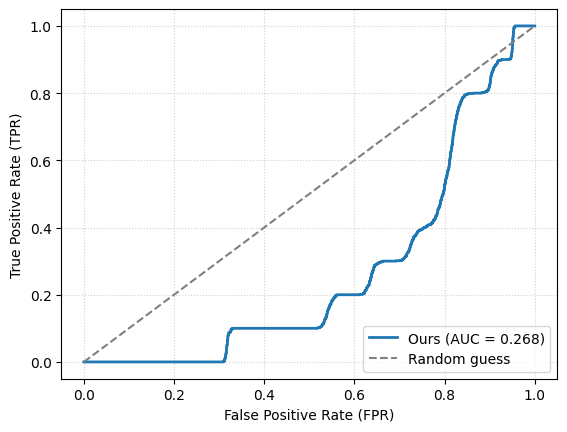

In [236]:
import math

# NOTE: classifier_weights only works if df_attack is the last index ran through the loop above!
reference = torch.linalg.norm(classifier_weights, dim=1).mean() * math.sqrt( 10 /(2 *(10-1)))
attacked = df_attack.filter(((pl.col("type") == "train") | (pl.col("type") == "test")))
scores = -(attacked["cd_0"].abs() - reference).abs()
plot_roc(attacked["type"] == "train", scores)

## Multi Reference Distance Estimated based on NC Understanding Leakage Free

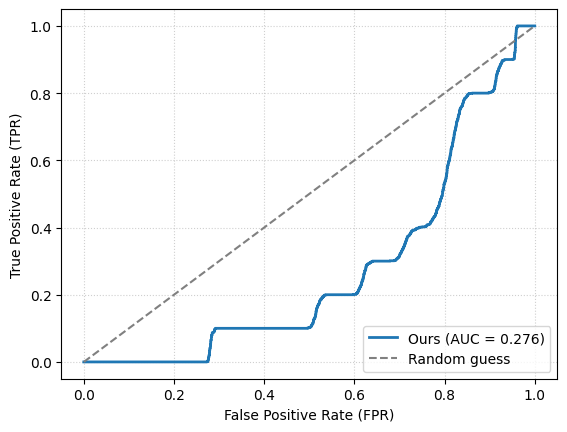

In [164]:
import math

# NOTE: classifier_weights only works if df_attack is the last index ran through the loop above!
references = torch.linalg.norm(classifier_weights, dim=1) * math.sqrt( 10 /(2 *(10-1)))
references = pl.DataFrame({"actual": list(range(len(references))), "reference": references.detach().numpy()})
attacked = df_attack.filter(((pl.col("type") == "train") | (pl.col("type") == "test"))).join(references, on="actual")
scores = -(attacked["cd_0"].abs() - attacked["reference"]).abs()
plot_roc(attacked["type"] == "train", scores)

## Multi Reference Distance Estimated based on Scale of Test and Direction of Means Leakage Free

Wir nehmen den Klassenmittelwert der Testdaten als Estimator für den echten Klassenmittelwert und berechnen mit denen die Distanz.

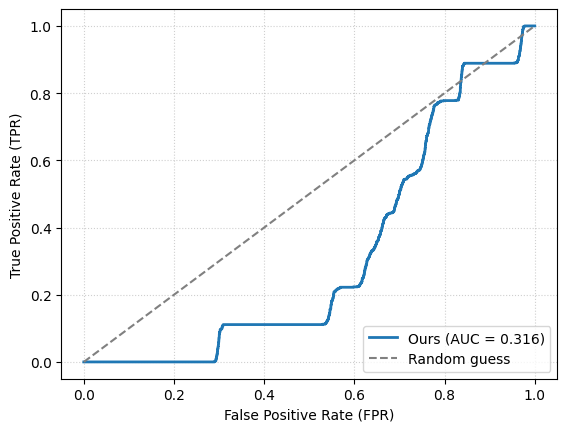

In [226]:
n = 200
fields = [f"f{i}" for i in range(n)]

df_filtered = df_attack.filter(pl.col("type") == "test")
means = (
    df_filtered
    .select("actual", pl.col("feature").arr.to_list().list.to_struct(fields=fields))
    .unnest("feature")
    .group_by("actual")
    .agg([pl.col(f).mean() for f in fields])
    .select(
        "actual",
        pl.concat_arr(*[pl.col(f).cast(pl.Float32) for f in fields]).alias("mean_feature"),
    )
)
# NOTE: classifier and classifier_weights only works if df_attack is the last index ran through the loop above!
logits = model.classifier()(torch.from_numpy(means["mean_feature"].to_numpy()))
iu, ju = torch.triu_indices(classifier_weights.shape[0], classifier_weights.shape[0], offset=1)
references = ((logits[:, iu] - logits[:, ju]) / w_dist[iu, ju])[0][:9] # The values for index 0 and the first 9 looked quite good but I have no explaining why we would choose exactly these.

references = pl.DataFrame({"actual": list(range(len(references))), "reference": references.detach().numpy()})
attacked = df_attack.filter(((pl.col("type") == "train") | (pl.col("type") == "test"))).join(references, on="actual")
scores = -(attacked["cd_0"].abs() - attacked["reference"]).abs()
plot_roc(attacked["type"] == "train", scores)

---

## Class Mean Distance with Leakage (based on Train data)

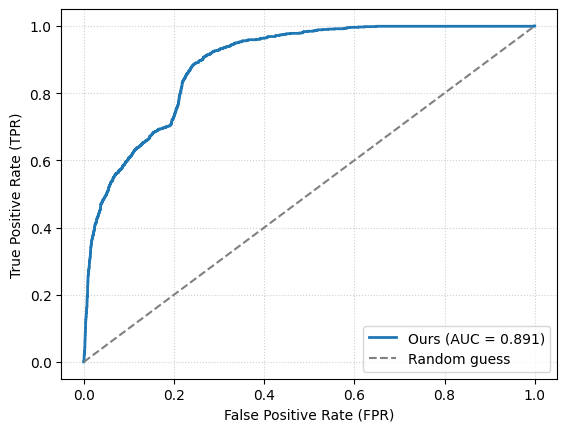

In [234]:
n = 200
fields = [f"f{i}" for i in range(n)]

df_filtered = df_attack.filter(pl.col("type") == "train")
means = (
    df_filtered
    .select("actual", pl.col("feature").arr.to_list().list.to_struct(fields=fields))
    .unnest("feature")
    .group_by("actual")
    .agg([pl.col(f).mean() for f in fields])
    .select(
        "actual",
        pl.concat_arr(*[pl.col(f).cast(pl.Float32) for f in fields]).alias("mean_feature"),
    )
)
attacked = df_attack.filter((pl.col("type") == "train") | (pl.col("type") == "test")).join(means, on="actual").with_columns(
    (pl.col("feature") - pl.col("mean_feature"))
        .arr.to_list()
        .list.eval(pl.element().pow(2))
        .list.sum()
        .sqrt()
        .alias("euclid_dist")
)
plot_roc(attacked["type"] == "train", -attacked["euclid_dist"])

## Class Mean Distance with Shadow Model Leakage Free 

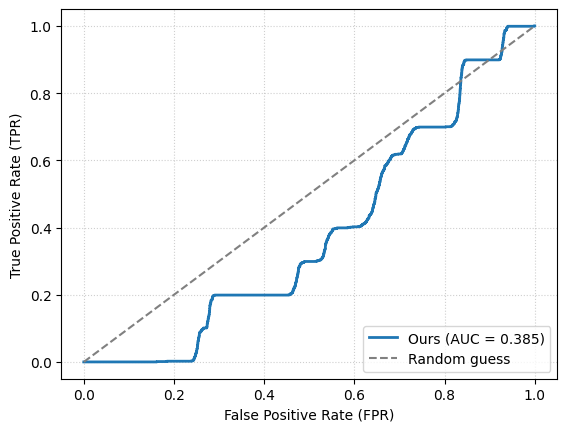

In [241]:
n = 200
fields = [f"f{i}" for i in range(n)]

df_filtered = df_shadow.filter(pl.col("type") == "train")
means = (
    df_filtered
    .select("actual", pl.col("feature").arr.to_list().list.to_struct(fields=fields))
    .unnest("feature")
    .group_by("actual")
    .agg([pl.col(f).mean() for f in fields])
    .select(
        "actual",
        pl.concat_arr(*[pl.col(f).cast(pl.Float32) for f in fields]).alias("mean_feature"),
    )
)
attacked = df_attack.filter((pl.col("type") == "train") | (pl.col("type") == "test")).join(means, on="actual").with_columns(
    (pl.col("feature") - pl.col("mean_feature"))
        .arr.to_list()
        .list.eval(pl.element().pow(2))
        .list.sum()
        .sqrt()
        .alias("euclid_dist")
)
plot_roc(attacked["type"] == "train", -attacked["euclid_dist"])

## Class Mean Distance using Test Data only Leakage Free

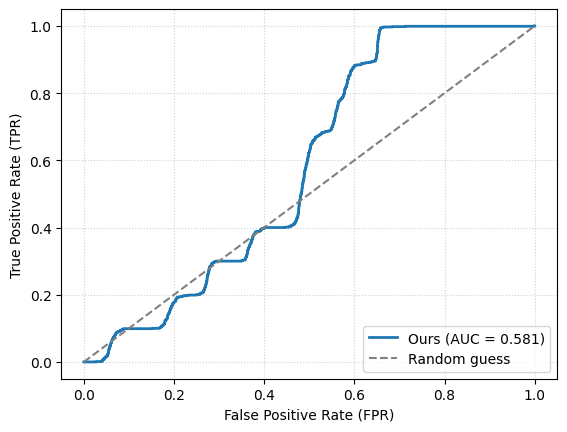

In [230]:
n = 200
fields = [f"f{i}" for i in range(n)]

df_filtered = df_attack.filter(pl.col("type") == "test")
means = (
    df_filtered
    .select("actual", pl.col("feature").arr.to_list().list.to_struct(fields=fields))
    .unnest("feature")
    .group_by("actual")
    .agg([pl.col(f).mean() for f in fields])
    .select(
        "actual",
        pl.concat_arr(*[pl.col(f).cast(pl.Float32) for f in fields]).alias("mean_feature"),
    )
)
attacked = df_attack.filter((pl.col("type") == "train") | (pl.col("type") == "test")).join(means, on="actual").with_columns(
    (pl.col("feature") - pl.col("mean_feature"))
        .arr.to_list()
        .list.eval(pl.element().pow(2))
        .list.sum()
        .sqrt()
        .alias("euclid_dist")
)
plot_roc(attacked["type"] == "train", -attacked["euclid_dist"])